# Flight delay prediction
**Grain:** 1 row per scheduled flight that arrived (2015 USDOT data).  
**Target:** `tgt_late` = arrival delay > 15 min.  
**Two prediction times, two models:**
- **A, schedule time** (days ahead). Features: `sched_*` (from the published schedule) and `hist_*` (late rates from earlier months).
- **B, day of operation**, 2 h before scheduled departure. Features: A plus `ops_*`, i.e. the state of the inbound aircraft and the origin airport at that moment.

**Split by time:** train Jan–Aug, validate Sep–Oct (early stopping), test Nov–Dec.  
Loading, the October airport-code mapping and the feature builders live in `src/flights.py`.

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.flights import (ROUTE, POST_DEPARTURE_COLS, load_flights, map_october_airports, add_times,
                         schedule_features, history_features, dayof_features)

SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
os.makedirs("outputs", exist_ok=True)

C:\Users\ferna\br_e-commerce\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("usdot/flight-delays")  # uses the local cache
dfs = load_flights(path)
flights = dfs["flights"]
code_map = map_october_airports(flights, dfs["airports"])
add_times(flights, lead_hours=2)
print(f"{len(flights):,} flights | October codes mapped: {len(code_map)}")
print("tz shift is a whole hour:", f"{(flights['tz_shift_min'] % 60 == 0).mean():.5%}")

5,819,079 flights | October codes mapped: 307
tz shift is a whole hour: 99.99966%


## 1. Target and split
Cancelled and diverted flights have no arrival delay, so they are excluded from the target here. They are still used as *events* for the day-of features, because a cancelled inbound flight is information available on the day.

In [3]:
flights["tgt_late"] = (flights["ARRIVAL_DELAY"] > 15).astype(float).where(flights["ARRIVAL_DELAY"].notna())
drops = pd.Series({"cancelled": flights["CANCELLED"].sum(), "diverted": flights["DIVERTED"].sum(),
                   "other missing arrival delay": (flights["tgt_late"].isna() & (flights["CANCELLED"] == 0)
                                                   & (flights["DIVERTED"] == 0)).sum()})
print("Rows without a target (excluded from modeling):"); print(drops)
assert drops.sum() == flights["tgt_late"].isna().sum()

flights["split"] = np.select([flights["MONTH"] <= 8, flights["MONTH"] <= 10], ["train", "val"], "test")
train_mask = flights["split"] == "train"
flights.loc[flights["tgt_late"].notna()].groupby("split")["tgt_late"].agg(rows="size", late_rate="mean").round(3)

Rows without a target (excluded from modeling):
cancelled                      89884
diverted                       15187
other missing arrival delay        0
dtype: int64


,rows,late_rate
split,,
test,932084,0.173
train,3836893,0.195
val,945031,0.121


## 2. Features
`MONTH` is deliberately **not** a feature, because test months are never seen in training. Seasonality enters through `sched_days_to_holiday` and the `hist_*` rates.

`hist_*` uses smoothed late rates. Val/test rows use Jan–Aug only, so the data is strictly earlier than theirs. Training rows use the *other* training months (out-of-fold), so a row never sees its own label.

In [4]:
schedule_features(flights)
HIST_GROUPS = {
    "route": ROUTE,
    "flight": ["AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT"],
    "airline_hour": ["AIRLINE", "sched_dep_hour"],
    "origin_hour": ["ORIGIN_AIRPORT", "sched_dep_hour"],
}
history_features(flights, "tgt_late", train_mask, HIST_GROUPS)
dayof_features(flights, window="3h")

FEAT_A = [c for c in flights.columns if c.startswith(("sched_", "hist_"))
          and c not in ("sched_dep_dt", "sched_arr_dt")]
FEAT_B = FEAT_A + [c for c in flights.columns if c.startswith("ops_")]
print(f"A: {len(FEAT_A)} features | B: {len(FEAT_B)} features")
flights[FEAT_B].isna().mean().loc[lambda s: s > 0].mul(100).round(1).rename("null_%")

A: 19 features | B: 30 features


sched_block_min               0.0
sched_dest_hour_arrs          0.0
ops_tail_leg_num              0.3
ops_inb_sched_turn_min        8.0
ops_inb_arr_delay            79.5
ops_inb_dep_delay            24.2
ops_inb_known_delay           8.0
ops_inb_delay_minus_turn      8.0
ops_origin_arr_late_rate     13.4
ops_origin_dep_delay_mean    12.2
Name: null_%, dtype: float64

### Leakage checks

In [5]:
# 1. No post-departure column is a feature
assert not set(FEAT_B) & set(POST_DEPARTURE_COLS)

# 2. Val/test hist rates equal a recomputation from training months only
tr = flights[train_mask]
prior = tr["tgt_late"].mean()
g = tr.groupby(ROUTE)["tgt_late"].agg(["sum", "count"])
chk = flights.loc[~train_mask, ROUTE + ["hist_route_late_rate"]].join(g, on=ROUTE)
expected = (chk["sum"].fillna(0) + 50 * prior) / (chk["count"].fillna(0) + 50)
assert np.allclose(chk["hist_route_late_rate"], expected)

# 3. Brute-force the day-of features on a random sample: inbound leg + airport window
rng = np.random.default_rng(SEED)
by_tail = flights[flights["TAIL_NUMBER"].notna()].groupby("TAIL_NUMBER")
for i in rng.choice(flights.index[flights["TAIL_NUMBER"].notna()], 300, replace=False):
    r = flights.loc[i]
    legs = by_tail.get_group(r["TAIL_NUMBER"])
    legs = legs[(legs["DESTINATION_AIRPORT"] == r["ORIGIN_AIRPORT"])
                & (legs["sched_arr_dt"] <= r["sched_dep_dt"])
                & (legs["sched_arr_dt"] >= r["sched_dep_dt"] - pd.Timedelta(hours=12))]
    if legs.empty:
        assert r["ops_inb_status"] == 0
        continue
    inb = legs.loc[legs["sched_arr_dt"].idxmax()]
    arrived = inb["act_arr_dt"] <= r["pred_dt"]          # both local to this origin
    assert arrived == (r["ops_inb_status"] == 3)
    if arrived:
        assert r["ops_inb_arr_delay"] == inb["ARRIVAL_DELAY"]
    else:
        assert np.isnan(r["ops_inb_arr_delay"])

arr = flights[["DESTINATION_AIRPORT", "act_arr_dt", "ARRIVAL_DELAY"]].dropna()
by_dest = arr.groupby("DESTINATION_AIRPORT")
for i in rng.choice(flights.index, 100, replace=False):
    r = flights.loc[i]
    a = by_dest.get_group(r["ORIGIN_AIRPORT"]) if r["ORIGIN_AIRPORT"] in by_dest.groups else arr.iloc[:0]
    w = a[(a["act_arr_dt"] > r["pred_dt"] - pd.Timedelta("3h")) & (a["act_arr_dt"] <= r["pred_dt"])]
    assert len(w) == r["ops_origin_arr_n"]
    assert len(w) == 0 or np.isclose((w["ARRIVAL_DELAY"] > 15).mean(), r["ops_origin_arr_late_rate"])
print("All leakage checks passed")

All leakage checks passed


## 3. Models

In [6]:
data = flights.loc[flights["tgt_late"].notna(), FEAT_B + ["tgt_late", "split"]]
parts = {s: data[data["split"] == s] for s in ["train", "val", "test"]}
y = {s: d["tgt_late"].astype(int) for s, d in parts.items()}
results, scores = [], {}

def evaluate(name, model_scores):
    scores[name] = model_scores
    for s in ["val", "test"]:
        p = model_scores[s]
        results.append({"model": name, "split": s, "PR_AUC": average_precision_score(y[s], p),
                        "ROC_AUC": roc_auc_score(y[s], p), "Brier": brier_score_loss(y[s], p)})

# Baseline 1: historical late rate of airline x departure hour
evaluate("B1 airline x hour rate", {s: parts[s]["hist_airline_hour_late_rate"] for s in ["val", "test"]})

# Baseline 2: logistic regression on schedule-time features (1M-row training sample)
num_a = [c for c in FEAT_A if parts["train"][c].dtype != "category"]
logit = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["sched_airline", "sched_dep_hour", "sched_dow"]),
                       ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_a)]),
    LogisticRegression(max_iter=1000))
sample = parts["train"].sample(1_000_000, random_state=SEED)
logit.fit(sample, sample["tgt_late"].astype(int))
evaluate("B2 logistic (A features)", {s: logit.predict_proba(parts[s])[:, 1] for s in ["val", "test"]})

In [7]:
def fit_lgbm(features):
    model = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.1, num_leaves=127, min_child_samples=500,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=SEED, verbose=-1)
    model.fit(parts["train"][features], y["train"],
              eval_X=parts["val"][features], eval_y=y["val"], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    print(f"best iteration: {model.best_iteration_}")
    return model

lgb_a = fit_lgbm(FEAT_A)
evaluate("A LightGBM (schedule time)", {s: lgb_a.predict_proba(parts[s][FEAT_A])[:, 1] for s in ["val", "test"]})
lgb_b = fit_lgbm(FEAT_B)
evaluate("B LightGBM (day of, -2h)", {s: lgb_b.predict_proba(parts[s][FEAT_B])[:, 1] for s in ["val", "test"]})

res = pd.DataFrame(results).pivot(index="model", columns="split").round(3)
res.columns = [f"{m}_{s}" for m, s in res.columns]
res = res.sort_values("PR_AUC_test")
res.to_csv("outputs/flights_model_metrics.csv")
print(f"Test base rate (PR-AUC of a random model): {y['test'].mean():.3f}")
res

best iteration: 7


best iteration: 135


Test base rate (PR-AUC of a random model): 0.173


,PR_AUC_test,PR_AUC_val,ROC_AUC_test,ROC_AUC_val,Brier_test,Brier_val
model,,,,,,
B1 airline x hour rate,0.232,0.168,0.609,0.616,0.141,0.111
B2 logistic (A features),0.240,0.188,0.619,0.639,0.141,0.111
A LightGBM (schedule time),0.241,0.176,0.620,0.631,0.140,0.110
"B LightGBM (day of, -2h)",0.564,0.470,0.783,0.764,0.108,0.085


## 4. Results

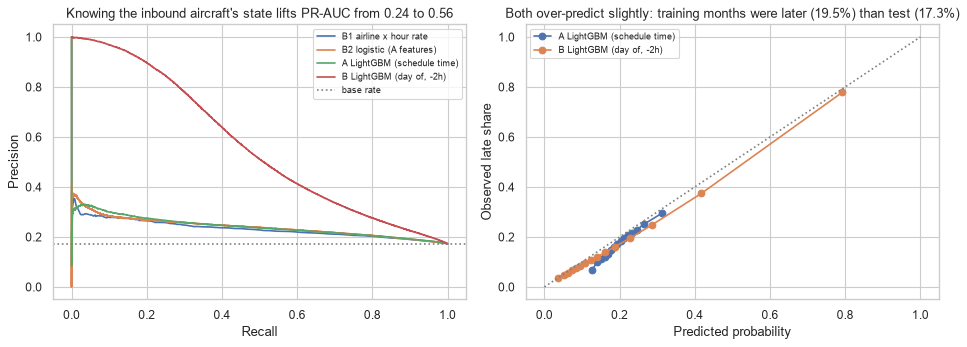

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, sc in scores.items():
    prec, rec, _ = precision_recall_curve(y["test"], sc["test"])
    axes[0].plot(rec, prec, label=name)
axes[0].axhline(y["test"].mean(), color="grey", ls=":", label="base rate")
axes[0].set(title="Knowing the inbound aircraft's state lifts PR-AUC from 0.24 to 0.56",
            xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8)
for name in ["A LightGBM (schedule time)", "B LightGBM (day of, -2h)"]:
    frac, mean_p = calibration_curve(y["test"], scores[name]["test"], n_bins=15, strategy="quantile")
    axes[1].plot(mean_p, frac, marker="o", label=name)
axes[1].plot([0, 1], [0, 1], color="grey", ls=":")
axes[1].set(title="Both over-predict slightly: training months were later (19.5%) than test (17.3%)", xlabel="Predicted probability", ylabel="Observed late share")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

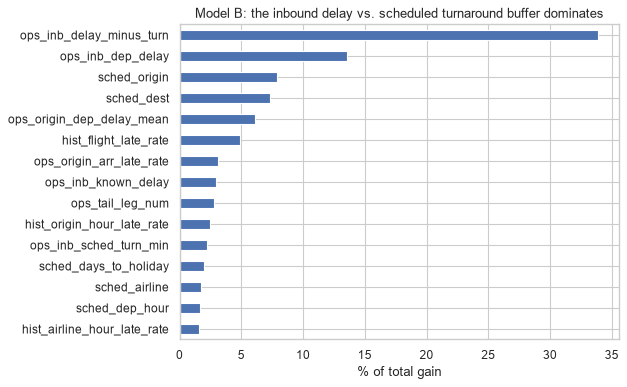

hist_flight_late_rate          43.9
hist_airline_hour_late_rate    20.9
hist_origin_hour_late_rate     11.0
sched_days_to_holiday           7.1
sched_dest                      6.0
sched_origin                    4.4
hist_flight_n                   1.7
hist_route_late_rate            1.6
Name: Model A: % gain, dtype: float64

In [9]:
imp = pd.DataFrame({
    "A": pd.Series(lgb_a.booster_.feature_importance("gain"), index=FEAT_A),
    "B": pd.Series(lgb_b.booster_.feature_importance("gain"), index=FEAT_B),
})
imp = imp.div(imp.sum()).mul(100)
ax = imp["B"].nlargest(15).sort_values().plot(kind="barh", figsize=(8, 5))
ax.set(title="Model B: the inbound delay vs. scheduled turnaround buffer dominates",
       xlabel="% of total gain", ylabel="")
plt.tight_layout(); plt.show()
imp["A"].nlargest(8).round(1).rename("Model A: % gain")

## 5. Conclusions
**At schedule time (model A), delay is barely predictable with this data.**
- Test PR-AUC is 0.24 vs a 0.17 base rate, and ROC-AUC is 0.62.
- LightGBM does no better than a logistic regression or a plain airline × hour lookup table. More regularization and dropping the airport categories didn't help either.
- Early stopping after about 7 trees shows that what the model learns from Jan–Aug doesn't carry over to Sep–Oct, which were much less delayed (12% vs 19.5% late).
- Most of the signal is how late *the same scheduled flight* was in other months (`hist_flight_late_rate`, 44% of gain).
- Without weather data and with only one year, a model can't capture much more than these historical averages.

**On the day of operation, 2 h before departure (model B), delay is predictable.**
- Test PR-AUC is 0.56 and ROC-AUC 0.78. At 40% recall the model is 64% precise, vs 24% for the lookup table. At 20% recall it is 90% precise.
- The strongest signal is the inbound aircraft's delay compared with its scheduled turnaround buffer (`ops_inb_delay_minus_turn`, 34% of gain). Next come the inbound departure delay (14%) and the origin airport's recent departure delays. This matches the EDA finding that late-arriving aircraft cause 40% of delay minutes.

**Caveats**
- Both models predict ~19–20% late on average vs 17.3% actual on test, because training months were more delayed. If the probabilities are used directly, recalibrate them on recent data.
- Validation (Sep–Oct) scores lower than test only because it's the least delayed period. PR-AUC depends on the base rate.
- Tail-number assignment is assumed to be known on the day, which is realistic for operations but not for passengers booking days ahead.

**Possible next steps**
- Run model B at several lead times (6 h, 2 h, 30 min) to see how accuracy grows as departure approaches.
- Add weather data (NOAA) for both models.
- Predict delay in minutes (regression).
- Retrain on a rolling window instead of a single fixed split.